**Practical 3 - Understand Descriptive Stats**

**Aim**:
To understand descriptive statistics and analyse the Student Rating Dataset using Python and data visualization techniques.

**Objectives**:
- To explore the columns of a dataset.
- To calculate percentages using Pandas.
- To calculate mean and standard deviation.
- To understand the distribution of data using histograms.
- To differentiate between vertical and horizontal bar charts.
- To calculate the median of evaluation scores.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/StudentRatingDataset_evals.csv')

**Q1. Exploring Dataset and Calculating Percentage**

In [ ]:
print(df.columns.tolist())

['score', 'rank', 'ethnicity', 'gender', 'language', 'age', 'cls_perc_eval', 'cls_did_eval', 'cls_students', 'cls_level', 'cls_profs', 'cls_credits', 'bty_f1lower', 'bty_f1upper', 'bty_f2upper', 'bty_m1lower', 'bty_m1upper', 'bty_m2upper', 'bty_avg', 'pic_outfit', 'pic_color']


In [ ]:
# Count minority professors who are tenured
minority_tenured = df[
    (df['ethnicity'] == 'minority') &
    (df['rank'] == 'tenured')
].shape[0]

# Count all minority professors
total_minority = (df['ethnicity'] == 'minority').sum()

# Calculate percentage
percentage = (minority_tenured / total_minority) * 100

print("Percentage of minority professors who are tenured:",
      percentage, "%")

Percentage of minority professors who are tenured: 40.625 %


**Interpretation**:

The analysis shows that **40.625% of minority professors hold tenure** in the given dataset.

This means that approximately 41 out of every 100 minority professors are tenured. The remaining professors belong to other rank categories.

The result provides an overview of the tenure status of minority professors in the dataset. However, a comparison with non-minority professors or a conclusion about statistical significance cannot be made from this calculation alone.


**Q2. Calculating Mean and Standard Deviation of Age**

In [ ]:
# Calculate mean and standard deviation of age by rank
age_stats = df.groupby('rank')['age'].agg(['mean', 'std'])

print(age_stats)

                   mean       std
rank                             
teaching      50.186275  6.946372
tenure track  38.388889  7.744559
tenured       51.889328  8.654502


In [ ]:
# Create a new tenure-status variable
df['tenure_status'] = df['rank'].apply(
    lambda x: 'Tenured' if x == 'tenured' else 'Untenured'
)

# Calculate mean and standard deviation
age_stats = df.groupby('tenure_status')['age'].agg(['mean', 'std'])

print(age_stats)

                    mean       std
tenure_status                     
Tenured        51.889328  8.654502
Untenured      44.119048  9.431705


**Interpretation**:

The mean age of tenured professors is approximately 51.89 years,
while the mean age of untenured professors is approximately 44.12 years.

This indicates that tenured professors are generally older than
untenured professors in this dataset.

**Q3. Visualising Age Distribution Using Histogram**

  For age, a histogram is the most appropriate graph because age is a numerical/continuous variable.
  
  A histogram groups ages into intervals and shows how frequently professors fall into each age group.

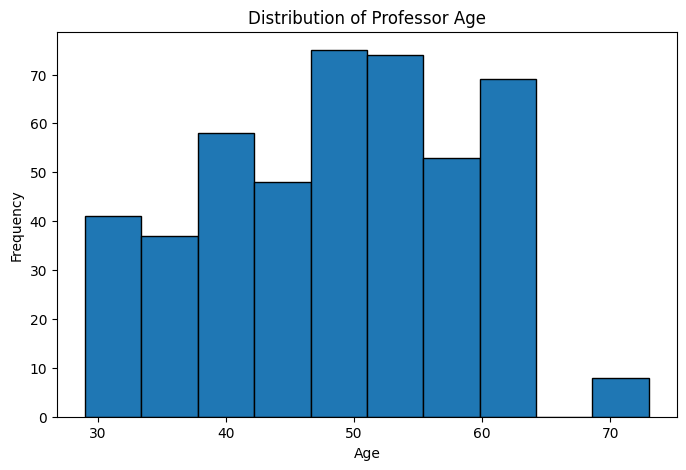

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=10, edgecolor='black')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Professor Age')

plt.show()

**Q4. Difference Between plt.bar() and plt.barh()**

plt.bar() creates a vertical bar chart.

plt.barh() creates a horizontal bar chart.

Both functions are used to represent categorical data graphically.

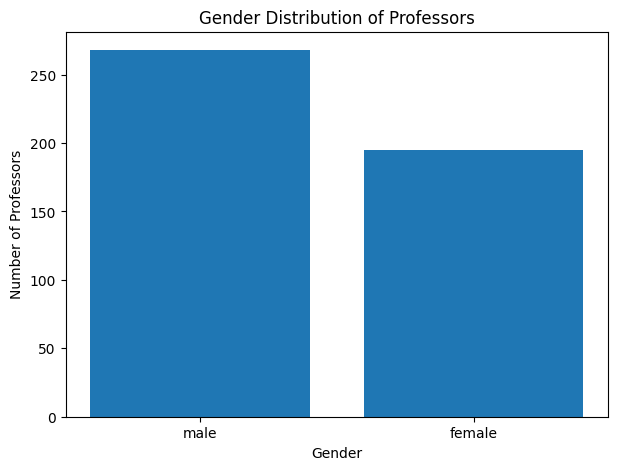

In [ ]:
# Count professors by gender
gender_counts = df['gender'].value_counts()

# Create vertical bar chart
plt.figure(figsize=(7, 5))

plt.bar(gender_counts.index, gender_counts.values)

plt.xlabel('Gender')
plt.ylabel('Number of Professors')
plt.title('Gender Distribution of Professors')

plt.show()

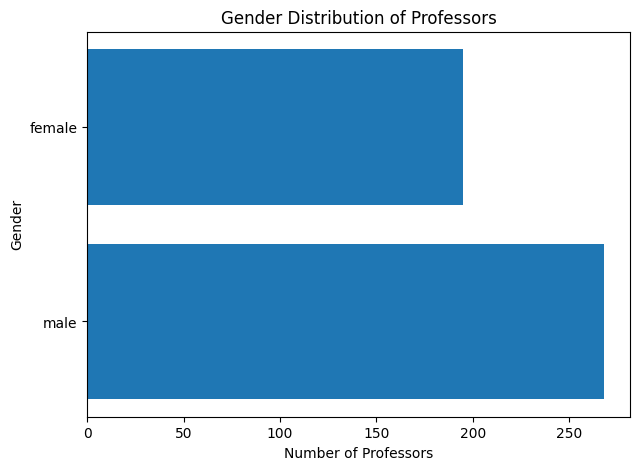

In [ ]:
plt.figure(figsize=(7, 5))

plt.barh(gender_counts.index, gender_counts.values)

plt.xlabel('Number of Professors')
plt.ylabel('Gender')
plt.title('Gender Distribution of Professors')

plt.show()

**Q5. Calculating Median Evaluation Score**

In [ ]:
# Select tenured professors
tenured = df[df['rank'] == 'tenured']

# Calculate median evaluation score
median_score = tenured['score'].median()

print("Median evaluation score for tenured professors:",
      median_score)

Median evaluation score for tenured professors: 4.2


**Conclusion**:

In this practical, descriptive statistical analysis was performed
using the Student Rating Dataset. Different statistical measures
such as percentage, mean, standard deviation and median were
calculated using Python.

Histograms and bar charts were also used to understand and
visualize the dataset.

This practical helped in understanding the application of
descriptive statistics and data visualization in data analysis.